# TESS Exoplanet Discovery Scanner

### Operating Instructions

1. **Initialize the Target Queue (Cell 1):** Run this cell once at the start of your session. It queries the MAST archive, removes known NASA planet hosts and previously scanned stars, and prepares a queue of unanalyzed Red Dwarfs.
2. **Load the Vetting Engine (Cell 2):** Run this cell once per session to define the light-curve stitching, Box Least Squares (BLS) periodogram, and false-positive filtering function in memory.
3. **Scan a Batch (Cell 3):** Run this cell to download and analyze the next 20 stars in the queue. Progress is logged automatically to `scanned_stars_log.csv`. To scan the next batch of 20 stars, simply re-run Cell 3 without re-running Cells 1 or 2.
4. **Review Batch Diagnostics (Cell 4):** Run this cell after Cell 3 completes to generate 3-panel diagnostic plots (periodogram, phase-folded dip, and odd/even depth comparison) for all signals exceeding the detection threshold.
5. **Inspect Individual Transit Passes (Cell 5):** Run this cell to view individual orbit passes side by side for passing candidates and optionally export verified targets to disk.

**Note:** If VS Code is closed or the Jupyter kernel is restarted, in-memory variables and loaded libraries are cleared. You must run all cells sequentially starting from Cell 1 to reinitialize the pipeline, though previously scanned stars in `scanned_stars_log.csv` will still be skipped automatically.

In [7]:
import os
import random
import warnings
warnings.filterwarnings("ignore", message=".*tpfmodel submodule.*")
warnings.filterwarnings("ignore", message=".*appears to be zero-centered.*")

import lightkurve as lk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astroquery.mast import Catalogs

LOG_FILE = "scanned_stars_log.csv"
BATCH_SIZE = 20

# Discovery engine targeting settings
SEARCH_MODE = "RANDOM_FIELD"   # Options: "RANDOM_FIELD" or "MANUAL"
MANUAL_CENTER = "TOI-700"      # Used only if SEARCH_MODE == "MANUAL"
SEARCH_RADIUS_DEG = 5.0
SHUFFLE_TARGETS = True

# Curated pool of 30 multi-sector TESS fields outside the crowded Galactic Plane
PRIME_TESS_FIELDS = [
    # Southern Continuous Viewing Zone & Deep Fields (Ecliptic South)
    ("TOI-700",      "Southern Continuous Viewing Zone (Dorado)"),
    ("L 98-59",      "Southern Deep Multi-Sector Field (Volans)"),
    ("LHS 1815",     "Southern Continuous Viewing Zone Edge (Pictor)"),
    ("TOI-270",      "Southern Deep Field (Pictor)"),
    ("WD 1856+534",  "Northern Continuous Viewing Zone (Draco)"),
    ("TOI-1452",     "Northern Continuous Viewing Zone (Draco)"),
    ("Kepler-1649",  "Northern High-Cadence Field (Cygnus High-Lat)"),
    ("TOI-175",      "Southern Deep Multi-Sector Field (Volans South)"),
    ("HD 21749",     "Southern Multi-Sector Field (Reticulum)"),
    ("Pi Mensae",    "Southern Continuous Viewing Zone Pole (Mensa)"),
    
    # Southern High-Galactic-Latitude Fields (Clean Photometry)
    ("LHS 1140",     "High-Latitude Southern Field (Cetus)"),
    ("LHS 3844",     "Southern Multi-Sector Field (Indus)"),
    ("GJ 357",       "Sub-Neptune / Rocky Zone (Hydra)"),
    ("LP 791-18",    "Temperate Red Dwarf Field (Crater)"),
    ("TRAPPIST-1",   "Equatorial Southern Boundary (Aquarius)"),
    ("GJ 1132",      "Southern Multi-Sector Field (Vela High-Lat)"),
    ("LHS 475",      "Southern Polar Octans Field (Octans)"),
    ("AU Mic",       "Southern Mid-Latitude Field (Microscopium)"),
    ("TOI-540",      "Southern Multi-Sector Field (Pictor West)"),
    ("LP 890-9",     "Southern Clean Background Field (Eridanus)"),
    
    # Northern High-Galactic-Latitude Fields (Clean Photometry)
    ("K2-18",        "High-Galactic-Latitude Field (Leo)"),
    ("GJ 1214",      "Northern Equatorial Deep Field (Ophiuchus)"),
    ("GJ 486",       "High-Latitude Northern Field (Virgo)"),
    ("Gliese 436",   "Northern High-Latitude Field (Leo Minor)"),
    ("HD 219134",    "Northern Multi-Sector Field (Cassiopeia Edge)"),
    ("GJ 3470",      "Northern Mid-Latitude Field (Cancer)"),
    ("TOI-1266",     "Northern High-Latitude Multi-Sector Field (Draco West)"),
    ("TOI-1685",     "Northern Winter Field (Taurus High-Lat)"),
    ("G 9-40",       "Northern Clean Background Field (Cancer South)"),
    ("Ross 128",     "Equatorial Clean Field (Virgo)")
]

# Load NASA's master list of known TESS Objects of Interest (TOIs)
toi_url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+tid,toi,tfopwg_disp+from+toi&format=csv"
toi_df = pd.read_csv(toi_url)
known_toi_ids = set(toi_df["tid"].dropna().astype(int))
print(f"Loaded {len(known_toi_ids)} unique stars with known NASA TOI signals.")

# Load the persistent log of stars already scanned in past runs
if os.path.exists(LOG_FILE):
    log_df = pd.read_csv(LOG_FILE)
    already_scanned_ids = set(
        log_df["TIC ID"].dropna().astype(str).str.replace("TIC ", "", regex=False).astype(int)
    )
    print(f"Loaded '{LOG_FILE}': Excluding {len(already_scanned_ids)} previously scanned stars.")
else:
    already_scanned_ids = set()
    print("No existing scan log found — 'scanned_stars_log.csv' will be created automatically.")

excluded_ids = known_toi_ids.union(already_scanned_ids)

# Select a TESS field and automatically skip any field that has 0 unscanned stars left
if SEARCH_MODE == "RANDOM_FIELD":
    field_candidates = random.sample(PRIME_TESS_FIELDS, len(PRIME_TESS_FIELDS))
else:
    field_candidates = [(MANUAL_CENTER, "Custom User-Selected Field")]

unanalyzed_dwarfs = pd.DataFrame()

for center_name, field_desc in field_candidates:
    print(f"\nSelected Sky Region: {center_name} — {field_desc} (radius={SEARCH_RADIUS_DEG} deg)")
    print("Querying MAST TIC with server-side filters...")
    
    raw_stars = Catalogs.query_criteria(
        objectname=center_name,
        radius=SEARCH_RADIUS_DEG,
        catalog="TIC",
        lumclass="DWARF",
        Teff=[2500, 4000],
        rad=[0.1, 0.5],
        Tmag=[6.0, 14.2]
    ).to_pandas()
    
    raw_stars["ID_int"] = raw_stars["ID"].astype(int)
    
    unanalyzed_dwarfs = (
        raw_stars[~raw_stars["ID_int"].isin(excluded_ids)]
        .dropna(subset=["Teff", "rad", "mass", "Jmag"])
    )
    
    if len(unanalyzed_dwarfs) > 0:
        SEARCH_CENTER = center_name
        FIELD_DESC = field_desc
        break
    else:
        print(f"All targets in {center_name} have already been scanned. Advancing to next field...")

# Shuffle or Sort the Target Queue
if len(unanalyzed_dwarfs) > 0:
    if SHUFFLE_TARGETS:
        unanalyzed_dwarfs = unanalyzed_dwarfs.sample(frac=1.0).reset_index(drop=True)
        order_msg = "randomly shuffled for unique discovery"
    else:
        unanalyzed_dwarfs = unanalyzed_dwarfs.sort_values("Tmag").reset_index(drop=True)
        order_msg = "sorted brightest-first"
    print(f"Ready: {len(unanalyzed_dwarfs)} unscanned Red Dwarfs queued up in {SEARCH_CENTER} ({order_msg}).")
    display(unanalyzed_dwarfs[["ID", "Tmag", "Teff", "rad", "mass", "Jmag"]].head(10))
else:
    print("All 30 curated TESS fields have been completely scanned.")

Loaded 7826 unique stars with known NASA TOI signals.
Loaded 'scanned_stars_log.csv': Excluding 60 previously scanned stars.

Selected Sky Region: TRAPPIST-1 — Equatorial Southern Boundary (Aquarius) (radius=5.0 deg)
Querying MAST TIC with server-side filters...
Ready: 305 unscanned Red Dwarfs queued up in TRAPPIST-1 (randomly shuffled for unique discovery).


,ID,Tmag,Teff,rad,mass,Jmag
0,278996687,13.3221,3664.0,0.494969,0.493062,11.954
1,33416816,13.7873,3620.0,0.413334,0.406449,12.420
2,176141628,14.1040,3547.0,0.434246,0.429533,12.701
3,248047558,13.5874,3292.0,0.396997,0.388086,11.911
4,49605660,12.1666,3788.0,0.473485,0.471249,10.908
5,36689462,13.5976,3342.0,0.467856,0.465408,12.034
6,188542604,14.0631,3446.0,0.311732,0.290047,12.574
7,278920498,12.9461,3319.0,0.391847,0.382247,11.294
8,404225147,14.1014,3375.0,0.399787,0.391239,12.534
9,36706924,12.9240,3496.0,0.361808,0.347838,11.470


In [ ]:
import os
import re
import shutil

warnings.filterwarnings("ignore", message=".*Mean of empty slice.*")
warnings.filterwarnings("ignore", message=".*Degrees of freedom <= 0.*")

def _safe_download(search_item):
    """
    Downloads a lightkurve search item, repairs corrupt cached .fits files if
    interrupted previously, and extracts clean (time, flux) arrays without
    failing on QLP files that have all-NaN flux_err columns.
    """
    try:
        raw_lc = search_item.download()
    except Exception as err:
        err_msg = str(err)
        match = re.search(r"(/[^\s]+\.fits|[A-Za-z]:\\[^\s]+\.fits)", err_msg)
        if match and os.path.exists(match.group(1)):
            corrupt_path = match.group(1)
            parent_dir = os.path.dirname(corrupt_path)
            print(f"  -> Removing corrupt cached file {os.path.basename(corrupt_path)} and re-downloading...")
            try:
                shutil.rmtree(parent_dir)
            except OSError:
                os.remove(corrupt_path)
            raw_lc = search_item.download()
        else:
            raise

    if raw_lc is None or len(raw_lc) == 0:
        return None

    t_val = np.asarray(raw_lc.time.value, dtype=float)
    f_val = np.asarray(raw_lc.flux.value, dtype=float)

    # Keep all cadences where time and flux are finite and positive (ignoring NaN flux_err)
    valid = np.isfinite(t_val) & np.isfinite(f_val) & (f_val > 0)
    if np.sum(valid) < 50:
        return None

    t_clean = t_val[valid]
    f_clean = f_val[valid] / np.nanmedian(f_clean := f_val[valid])

    return lk.LightCurve(time=t_clean, flux=f_clean)


def scan_star_for_transits(star_row, max_sectors=3):
    """
    Stitches up to 3 contiguous TESS sectors, runs a 10,000-point BLS periodogram,
    and applies 6 automated false-positive vetting checks.
    """
    tic_id = f"TIC {int(star_row['ID'])}"
    R_star = float(star_row["rad"])
    M_star = float(star_row["mass"])
    T_star = float(star_row["Teff"])
    J_mag  = float(star_row["Jmag"])

    # Single MAST query filtered in memory
    search_all = lk.search_lightcurve(tic_id, mission="TESS")
    if len(search_all) == 0:
        print(f"  -> No TESS light curve product found on MAST for {tic_id}")
        return None, None, None

    tbl = search_all.table
    spoc_120 = (tbl["author"] == "SPOC") & (tbl["exptime"] == 120)
    tess_spoc = (tbl["author"] == "TESS-SPOC") & (tbl["exptime"] >= 120)
    qlp_standard = (tbl["author"] == "QLP") & (tbl["exptime"] >= 120)

    if np.any(spoc_120):
        search = search_all[spoc_120]
    elif np.any(tess_spoc):
        search = search_all[tess_spoc]
    elif np.any(qlp_standard):
        search = search_all[qlp_standard]
    else:
        print(f"  -> No standard-cadence SPOC/QLP light curve for {tic_id}")
        return None, None, None

    # Pick up to 'max_sectors' from the latest CONTIGUOUS observing season (<120 days apart)
    lc_list = []
    latest_start = None

    for idx in range(len(search) - 1, -1, -1):
        if len(lc_list) >= max_sectors:
            break
        candidate_lc = _safe_download(search[idx])
        if candidate_lc is None:
            continue
        if latest_start is None:
            lc_list.append(candidate_lc)
            latest_start = float(candidate_lc.time.value.min())
        else:
            cand_end = float(candidate_lc.time.value.max())
            if (latest_start - cand_end) <= 120.0:
                lc_list.insert(0, candidate_lc)
                latest_start = float(candidate_lc.time.value.min())
            else:
                break

    if len(lc_list) == 0:
        print(f"  -> All downloaded sectors for {tic_id} contained empty/NaN flux arrays")
        return None, None, None

    n_sec = len(lc_list)

    lc_stitched = lk.LightCurveCollection(lc_list).stitch().remove_nans()
    if len(lc_stitched) < 100:
        print(f"  -> Insufficient valid data points ({len(lc_stitched)}) for {tic_id}")
        return None, None, None

    lc_flat = (
        lc_stitched
        .flatten(window_length=301)
        .remove_outliers(sigma_lower=10.0, sigma_upper=3.0)
    )

    # Run BLS on a 10,000-point period grid (1.1 to 11.5 days)
    period_grid = np.linspace(1.1, 11.5, 10000)
    duration_grid = np.linspace(0.04, 0.15, 10)
    bls = lc_flat.to_periodogram(method="bls", period=period_grid, duration=duration_grid)

    period = float(bls.period_at_max_power.value)
    t0 = float(bls.transit_time_at_max_power.value)
    duration = float(bls.duration_at_max_power.value)
    depth = float(bls.depth_at_max_power.value)

    # Detrend BLS power spectrum to compute clean SDE
    power_vals = np.asarray(bls.power.value, dtype=float)
    rolling_med = pd.Series(power_vals).rolling(500, center=True, min_periods=1).median().to_numpy()
    detrended_power = power_vals - rolling_med
    sde = float(detrended_power.max() / np.nanstd(detrended_power))

    # Extract time & flux arrays for physical vetting tests
    t_arr = np.asarray(lc_flat.time.value, dtype=float)
    f_arr = np.asarray(lc_flat.flux.value, dtype=float)

    phase_days = (t_arr - t0 + 0.5 * period) % period - 0.5 * period
    in_transit = np.abs(phase_days) <= (0.5 * duration)
    out_of_transit = np.abs(phase_days) > duration

    n_points_in_transit = int(np.sum(in_transit))
    orbit_nums_all = np.round((t_arr - t0) / period).astype(int)
    unique_orbits = np.unique(orbit_nums_all[in_transit])
    n_distinct_transits = int(len(unique_orbits))

    median_dip_depth = float(1.0 - np.nanmedian(f_arr[in_transit])) if n_points_in_transit > 0 else 0.0

    # Flat Baseline vs. Rotational Wave / Noisy Flat-Liner Check
    oot_phases = phase_days[out_of_transit]
    oot_fluxes = f_arr[out_of_transit]
    bins = np.linspace(-0.5 * period, 0.5 * period, 51)
    bin_indices = np.digitize(oot_phases, bins)
    binned_oot = [np.nanmedian(oot_fluxes[bin_indices == b]) for b in range(1, 51) if np.sum(bin_indices == b) >= 3]
    oot_wave_std = float(np.nanstd(binned_oot)) if len(binned_oot) > 5 else 1e-3
    dip_to_wave_ratio = float(median_dip_depth / max(oot_wave_std, 1e-6))

    # Per-Transit Pass Consistency (Do >=75% of individual orbits actually dip?)
    valid_passes = 0
    dipped_passes = 0
    for orb in unique_orbits:
        orb_mask = in_transit & (orbit_nums_all == orb)
        if np.sum(orb_mask) >= 2:
            valid_passes += 1
            if (1.0 - np.nanmedian(f_arr[orb_mask])) > (0.35 * depth):
                dipped_passes += 1
    pass_consistency_pct = float((dipped_passes / max(valid_passes, 1)) * 100.0)

    # Odd vs. Even Transit Depth Check
    double_p = period * 2.0
    odd_in = np.abs((t_arr - t0 + 0.5 * double_p) % double_p - 0.5 * double_p) <= (0.5 * duration)
    even_in = np.abs((t_arr - (t0 + period) + 0.5 * double_p) % double_p - 0.5 * double_p) <= (0.5 * duration)
    odd_depth = float(1.0 - np.nanmedian(f_arr[odd_in])) if np.any(odd_in) else depth
    even_depth = float(1.0 - np.nanmedian(f_arr[even_in])) if np.any(even_in) else depth
    odd_even_diff_pct = float(abs(odd_depth - even_depth) / max(abs(odd_depth), abs(even_depth), 1e-6) * 100.0)

    # Calculate Planet Properties & JWST TSM Score
    r_earth = float(R_star * np.sqrt(max(depth, 0.0)) * 109.076)
    a_au = float((M_star * (period / 365.25) ** 2) ** (1 / 3))
    t_eq = float(T_star * np.sqrt(R_star / (2 * a_au * 215.032)) * ((1 - 0.3) ** 0.25))

    m_earth = r_earth ** 2.06 if r_earth < 1.23 else 1.436 * (r_earth ** 1.7)
    scale_fac = 0.190 if r_earth < 1.5 else 1.26
    tsm = float(scale_fac * ((r_earth ** 3) * t_eq / (m_earth * (R_star ** 2))) * (10 ** (-J_mag / 5)))

    # Automated Vetting Verdict Waterfall
    if n_distinct_transits < 3 or n_points_in_transit < 8 or median_dip_depth <= 0.0002:
        vet_status = f"Reject: Gap Glitch ({n_distinct_transits} transits)"
    elif r_earth >= 8.0:
        vet_status = "Reject: Too Large (EB)"
    elif dip_to_wave_ratio < 2.5:
        vet_status = f"Reject: Wavy/Noisy Baseline (SNR={dip_to_wave_ratio:.1f})"
    elif pass_consistency_pct < 75.0:
        vet_status = f"Reject: Inconsistent Passes ({dipped_passes}/{valid_passes})"
    elif odd_even_diff_pct > 50.0:
        vet_status = "Reject: Odd/Even Asymmetry"
    elif sde >= 6.5:
        vet_status = "PASS: Coherent Candidate"
    else:
        vet_status = "Weak / Noise Floor"

    result = {
        "TIC ID": tic_id,
        "Sectors": int(n_sec),
        "SDE (Signal Strength)": round(sde, 2),
        "Period (d)": round(period, 4),
        "Transits": f"{dipped_passes}/{valid_passes}",
        "Dip SNR": round(dip_to_wave_ratio, 2),
        "Est. Radius (R_earth)": round(r_earth, 2),
        "Odd/Even Diff (%)": round(odd_even_diff_pct, 1),
        "JWST TSM": round(tsm, 1),
        "Vetting Verdict": vet_status
    }
    return result, lc_flat, bls

In [16]:
import signal

TIMEOUT_SECONDS = 180
HAS_SIGALRM = hasattr(signal, "SIGALRM")

class StarTimeoutError(Exception):
    pass

def _timeout_handler(signum, frame):
    raise StarTimeoutError(f"Exceeded {TIMEOUT_SECONDS}s limit")

if HAS_SIGALRM:
    signal.signal(signal.SIGALRM, _timeout_handler)

if len(unanalyzed_dwarfs) == 0:
    print("All stars in this region have been scanned and logged.")
    print("To explore a new patch of sky, re-run Cell 1.")
else:
    target_batch = unanalyzed_dwarfs.head(BATCH_SIZE).copy()
    print(f"Scanning next {len(target_batch)} unscanned stars ({len(unanalyzed_dwarfs)} remaining in queue)...")
    
    results = []
    high_sde_candidates = {}
    scanned_this_run = []
    
    for idx, (_, star_row) in enumerate(target_batch.iterrows(), 1):
        tic_name = f"TIC {int(star_row['ID'])}"
        print(f"[{idx}/{len(target_batch)}] Scanning {tic_name} (Tmag={star_row['Tmag']:.2f}, Teff={star_row['Teff']:.0f}K)...")
        
        if HAS_SIGALRM:
            signal.alarm(TIMEOUT_SECONDS)
        try:
            res, lc_flat, bls = scan_star_for_transits(star_row, max_sectors=3)
            if HAS_SIGALRM:
                signal.alarm(0)
            if res is not None:
                results.append(res)
                scanned_this_run.append(res)
                if res["SDE (Signal Strength)"] >= 6.4:
                    high_sde_candidates[tic_name] = (res, lc_flat, bls)
            else:
                scanned_this_run.append({"TIC ID": tic_name, "Vetting Verdict": "No TESS Light Curve"})
        except Exception as e:
            if HAS_SIGALRM:
                signal.alarm(0)
            print(f"  -> Skipped {tic_name} (not logged to CSV so it can be retried later): {e}")
            
    # Permanently append completed stars from this batch to 'scanned_stars_log.csv'
    if len(scanned_this_run) > 0:
        batch_log_df = pd.DataFrame(scanned_this_run)
        if os.path.exists(LOG_FILE):
            existing_log = pd.read_csv(LOG_FILE)
            combined_log = pd.concat([existing_log, batch_log_df], ignore_index=True).drop_duplicates(subset=["TIC ID"], keep="last")
            combined_log.to_csv(LOG_FILE, index=False)
        else:
            batch_log_df.to_csv(LOG_FILE, index=False)
        
    # Remove the batch from the active in-memory queue
    unanalyzed_dwarfs = unanalyzed_dwarfs.iloc[len(target_batch):].reset_index(drop=True)
    print(f"\nBatch logged to '{LOG_FILE}'. {len(unanalyzed_dwarfs)} unscanned stars remaining in queue.")
    
    # Display the ranked multi-sector leaderboard (PASS candidates first, then sorted by SDE)
    if len(results) > 0:
        leaderboard = pd.DataFrame(results)
        leaderboard["_pass_sort"] = leaderboard["Vetting Verdict"].str.startswith("PASS")
        leaderboard = (
            leaderboard.sort_values(["_pass_sort", "SDE (Signal Strength)"], ascending=[False, False])
            .drop(columns=["_pass_sort"])
            .reset_index(drop=True)
        )
        display(leaderboard)
        print(f"Saved {len(high_sde_candidates)} signals with SDE >= 6.4 for visual plotting in Cell 4.")
    else:
        print("No valid light curves returned in this batch.")

Scanning next 20 unscanned stars (265 remaining in queue)...
[1/20] Scanning TIC 4518554 (Tmag=13.48, Teff=2971K)...
[2/20] Scanning TIC 278868009 (Tmag=13.22, Teff=3356K)...
[3/20] Scanning TIC 33423426 (Tmag=10.74, Teff=3617K)...
[4/20] Scanning TIC 4425971 (Tmag=13.59, Teff=3592K)...
[5/20] Scanning TIC 4601903 (Tmag=14.10, Teff=3641K)...
[6/20] Scanning TIC 4609881 (Tmag=13.22, Teff=2844K)...
[7/20] Scanning TIC 224220313 (Tmag=12.55, Teff=3592K)...
[8/20] Scanning TIC 301080220 (Tmag=12.84, Teff=3427K)...
[9/20] Scanning TIC 4580690 (Tmag=13.63, Teff=3315K)...
[10/20] Scanning TIC 49593127 (Tmag=13.97, Teff=3594K)...
  -> Skipped TIC 49593127 (not logged to CSV so it can be retried later): ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))
[11/20] Scanning TIC 49605530 (Tmag=12.65, Teff=3534K)...
  -> Skipped TIC 49605530 (not logged to CSV so it can be retried later): ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))
[12/20

,TIC ID,Sectors,SDE (Signal Strength),Period (d),Transits,Dip SNR,Est. Radius (R_earth),Odd/Even Diff (%),JWST TSM,Vetting Verdict
0,TIC 4425971,1,17.27,6.7280,1/1,104.39,18.07,1.3,349.1,Reject: Gap Glitch (1 transits)
1,TIC 4609881,1,12.10,1.1416,19/20,1.26,1.13,18.7,30.1,Reject: Wavy/Noisy Baseline (SNR=1.3)
2,TIC 4518554,1,8.29,2.3627,6/11,3.18,11.96,50.4,926.4,Reject: Too Large (EB)
3,TIC 4601903,1,7.05,6.7030,1/1,13.17,11.64,5.0,145.7,Reject: Gap Glitch (1 transits)
4,TIC 4580690,1,6.42,3.2624,5/6,5.32,1.66,47.0,45.3,Weak / Noise Floor
5,TIC 224220313,1,6.15,11.4532,1/1,24.86,4.67,2.0,62.4,Reject: Gap Glitch (1 transits)
6,TIC 33423426,1,6.04,6.3182,3/3,3.77,1.41,45.9,5.9,Weak / Noise Floor
7,TIC 278868009,1,5.46,5.8959,3/4,4.13,1.89,12.6,34.2,Weak / Noise Floor
8,TIC 301080220,1,5.16,9.2045,2/2,10.22,2.11,16.7,28.8,Reject: Gap Glitch (2 transits)


Saved 5 signals with SDE >= 6.4 for visual plotting in Cell 4.


## Part 1: 3-Panel Diagnostic Vetting Cheat Sheet (Cell 4)

Use these three 5-second visual rules to evaluate each candidate's **BLS Periodogram**, **Phase-Folded Dip**, and **Odd vs. Even Transit Check**:

| Panel | Rule Name | ✅ Real Planet Candidate | ❌ False Alarm / Noise |
| :--- | :--- | :--- | :--- |
| **1. Left Plot**<br>*(BLS Periodogram)* | **The "Skyscraper vs. Tall Grass" Rule** | A sharp needle inside the gold highlight bar that stands **at least 2x taller** than the surrounding background spikes. | **Tall Grass:** Dozens of random navy spikes across the chart are almost as tall as the peak inside the gold bar. |
| **2. Middle Plot**<br>*(Phase-Folded Dip)* | **The "Bowl vs. Ruler" Rule** | The crimson binned line sits flat along `1.000` on the left and right shoulders, dropping into a **distinct, localized U-shaped bowl** at `Phase = 0.0`. | **Flat Ruler or Sine Wave:** The crimson line looks flat across `0.0`, or curves continuously like a wide roller-coaster wave across the entire window. |
| **3. Right Plot**<br>*(Odd vs. Even Check)* | **The "Blue & Orange Shadow" Rule** | The solid blue line (**Odd Transits**) and dashed orange line (**Even Transits**) trace the **exact same U-shaped valley together** like shadows. | **Out-of-Sync or Asymmetric:** One line bumps upward while the other drops, or one color is more than $50\%$ deeper than the other. |

> **Watch Out for Auto-Zoom on the Right Plot:** Matplotlib automatically zooms the Y-axis of the right-hand plot to fit the binned lines. Always check the Y-axis numbers (`0.9995` vs `0.9950`) and verify that the dip is genuinely visible in the middle plot first

![3-Panel Vetting Guide](ref_3panel_guide.png)


[1/5] === TIC 4425971 | Reject: Gap Glitch (1 transits) ===
SDE: 17.27 | Period: 6.7280 d | Passes Dipped: 1/1 | Dip SNR: 104.39 | Radius: 18.07 R_earth | TSM: 349.1


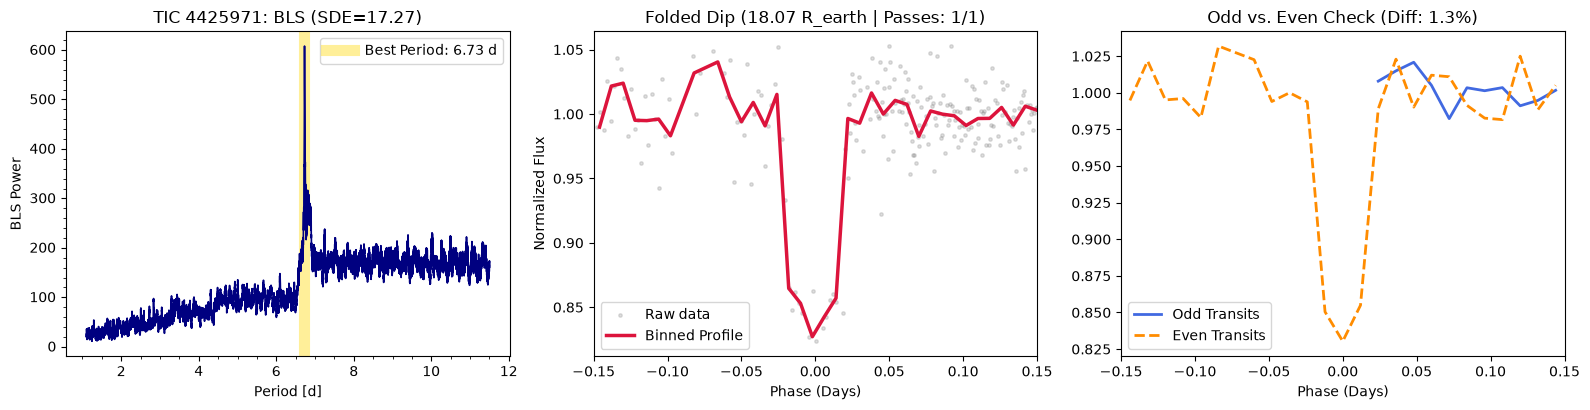


[2/5] === TIC 4609881 | Reject: Wavy/Noisy Baseline (SNR=1.3) ===
SDE: 12.1 | Period: 1.1416 d | Passes Dipped: 19/20 | Dip SNR: 1.26 | Radius: 1.13 R_earth | TSM: 30.1


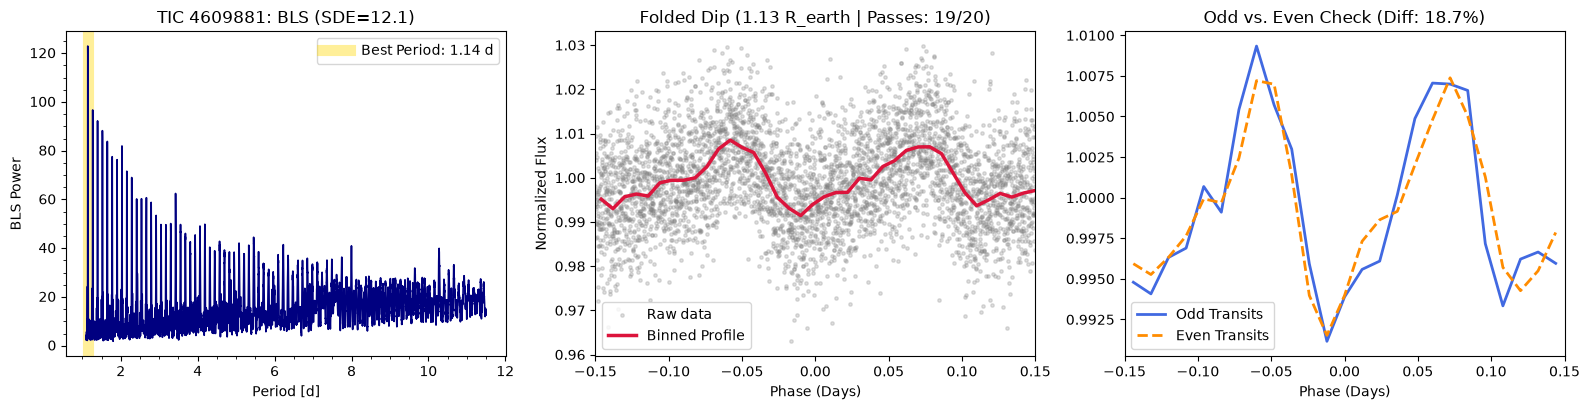


[3/5] === TIC 4518554 | Reject: Too Large (EB) ===
SDE: 8.29 | Period: 2.3627 d | Passes Dipped: 6/11 | Dip SNR: 3.18 | Radius: 11.96 R_earth | TSM: 926.4


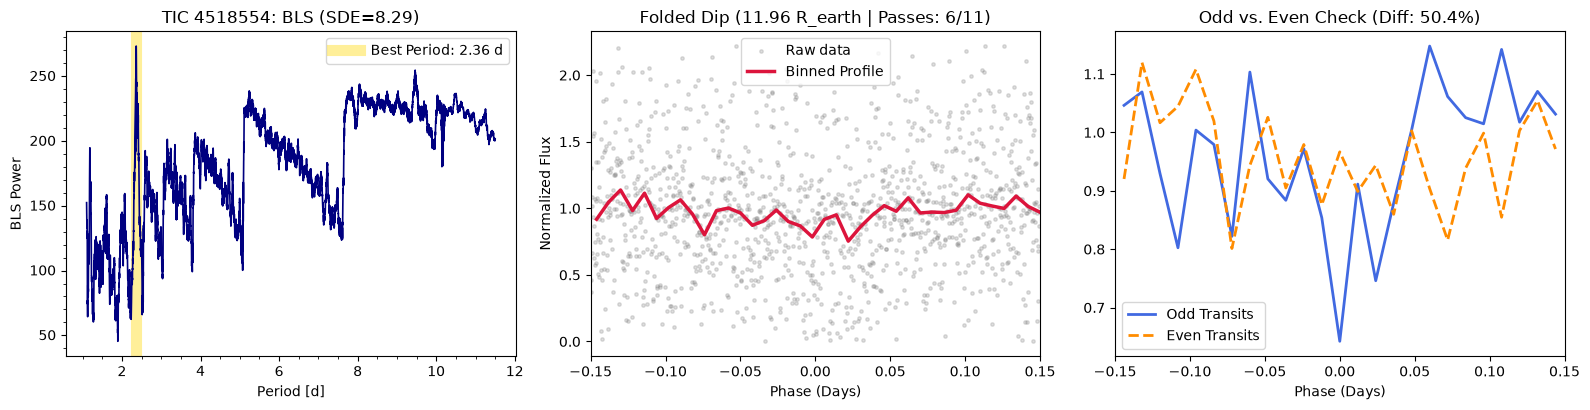


[4/5] === TIC 4601903 | Reject: Gap Glitch (1 transits) ===
SDE: 7.05 | Period: 6.7030 d | Passes Dipped: 1/1 | Dip SNR: 13.17 | Radius: 11.64 R_earth | TSM: 145.7


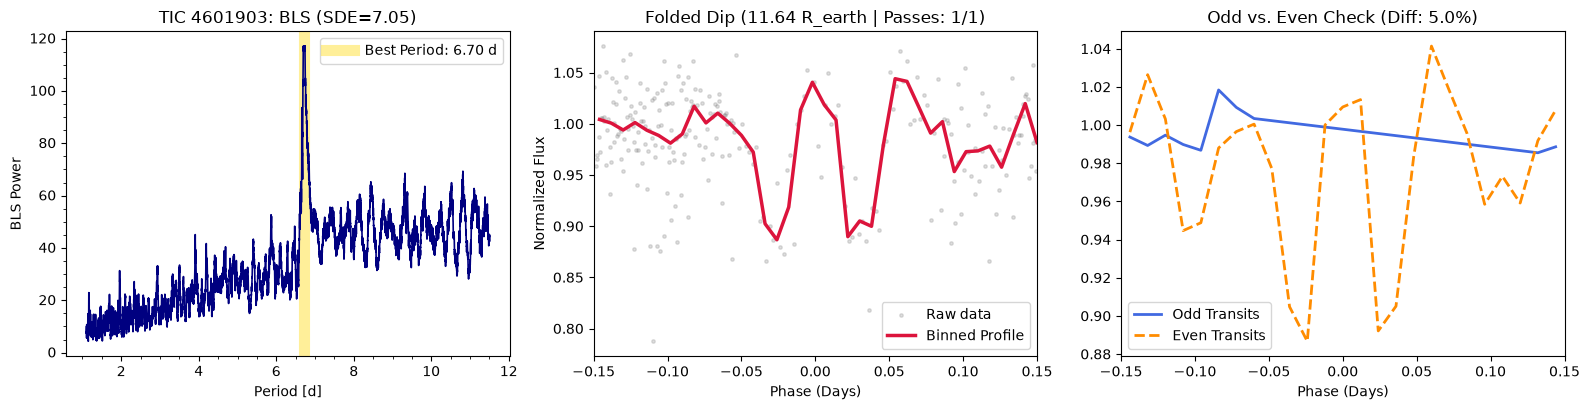


[5/5] === TIC 4580690 | Weak / Noise Floor ===
SDE: 6.42 | Period: 3.2624 d | Passes Dipped: 5/6 | Dip SNR: 5.32 | Radius: 1.66 R_earth | TSM: 45.3


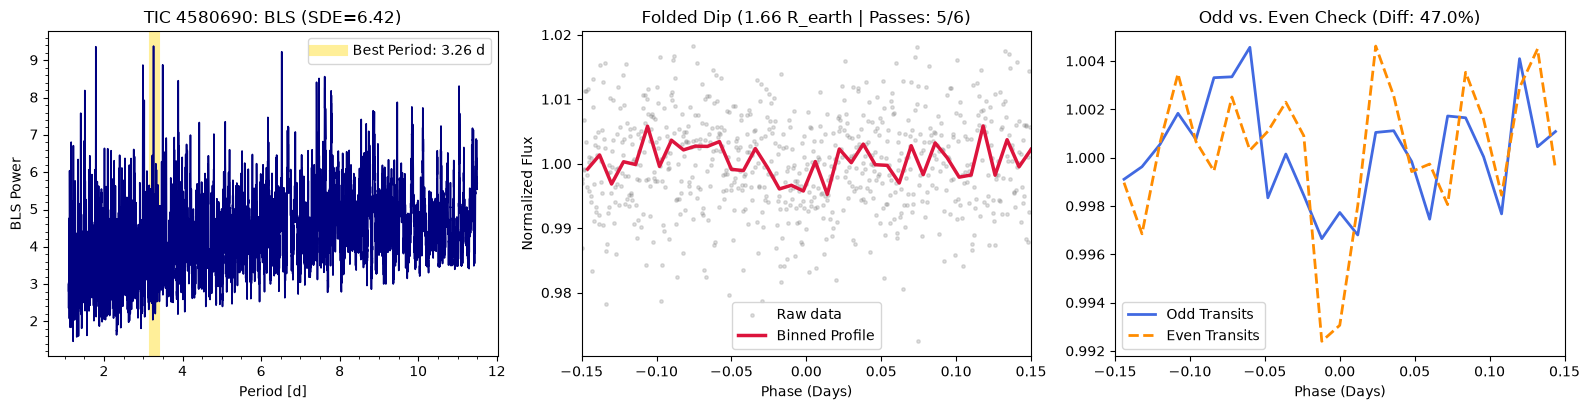

In [17]:
def _fast_phase_bin(phase_arr, flux_arr, bin_width=0.008, x_lim=0.15):
    """
    Bins phase-folded time and flux arrays directly in NumPy, bypassing
    Astropy's aggregate_downsample MaskedColumn shape mismatch bug on QLP data.
    """
    edges = np.arange(-x_lim, x_lim + bin_width, bin_width)
    centers = 0.5 * (edges[:-1] + edges[1:])
    idx = np.digitize(phase_arr, edges)
    
    b_x, b_y = [], []
    for i in range(1, len(edges)):
        mask = (idx == i) & np.isfinite(flux_arr)
        if np.sum(mask) >= 2:
            b_x.append(centers[i - 1])
            b_y.append(np.nanmedian(flux_arr[mask]))
    return np.array(b_x), np.array(b_y)

if len(high_sde_candidates) == 0:
    print("No candidates reached the SDE >= 6.4 threshold in this batch.")
else:
    sorted_candidates = sorted(
        high_sde_candidates.values(),
        key=lambda x: ("PASS" in x[0]["Vetting Verdict"], x[0]["SDE (Signal Strength)"]),
        reverse=True
    )
    
    for rank, (res, lc, bls) in enumerate(sorted_candidates, 1):
        p = res["Period (d)"]
        t0 = float(bls.transit_time_at_max_power.value)
        
        print(f"\n[{rank}/{len(sorted_candidates)}] === {res['TIC ID']} | {res['Vetting Verdict']} ===")
        print(
            f"SDE: {res['SDE (Signal Strength)']} | Period: {p:.4f} d | "
            f"Passes Dipped: {res['Transits']} | Dip SNR: {res['Dip SNR']} | "
            f"Radius: {res['Est. Radius (R_earth)']} R_earth | TSM: {res['JWST TSM']}"
        )
        
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.2))
        
        # BLS Periodogram
        bls.plot(ax=ax1, color="navy", lw=1.2, zorder=3)
        ax1.axvline(p, color="gold", lw=8, alpha=0.4, zorder=0, label=f"Best Period: {p:.2f} d")
        ax1.set_title(f"{res['TIC ID']}: BLS (SDE={res['SDE (Signal Strength)']})")
        ax1.legend()
        
        # Extract raw NumPy arrays once for Panels 2 and 3
        t_arr = np.asarray(lc.time.value, dtype=float)
        f_arr = np.asarray(lc.flux.value, dtype=float)
        
        # Phase-Folded Transit Dip
        phase_1x = (t_arr - t0 + 0.5 * p) % p - 0.5 * p
        win_1x = np.abs(phase_1x) <= 0.15
        ax2.scatter(phase_1x[win_1x], f_arr[win_1x], color="gray", alpha=0.25, s=6, label="Raw data")
        
        bx, by = _fast_phase_bin(phase_1x[win_1x], f_arr[win_1x], bin_width=0.008, x_lim=0.15)
        if len(bx) > 0:
            ax2.plot(bx, by, color="crimson", lw=2.5, label="Binned Profile")
        ax2.set_xlim(-0.15, 0.15)
        ax2.set_title(f"Folded Dip ({res['Est. Radius (R_earth)']} R_earth | Passes: {res['Transits']})")
        ax2.set_xlabel("Phase (Days)")
        ax2.set_ylabel("Normalized Flux")
        ax2.legend()
        
        # Odd vs. Even Transit Overlay
        p2 = p * 2.0
        phase_odd = (t_arr - t0 + 0.5 * p2) % p2 - 0.5 * p2
        phase_even = (t_arr - (t0 + p) + 0.5 * p2) % p2 - 0.5 * p2
        
        ox, oy = _fast_phase_bin(phase_odd[np.abs(phase_odd) <= 0.15], f_arr[np.abs(phase_odd) <= 0.15], bin_width=0.012, x_lim=0.15)
        ex, ey = _fast_phase_bin(phase_even[np.abs(phase_even) <= 0.15], f_arr[np.abs(phase_even) <= 0.15], bin_width=0.012, x_lim=0.15)
        
        if len(ox) > 0:
            ax3.plot(ox, oy, color="royalblue", lw=2, label="Odd Transits")
        if len(ex) > 0:
            ax3.plot(ex, ey, color="darkorange", lw=2, linestyle="--", label="Even Transits")
        ax3.set_xlim(-0.15, 0.15)
        ax3.set_title(f"Odd vs. Even Check (Diff: {res['Odd/Even Diff (%)']}%)")
        ax3.set_xlabel("Phase (Days)")
        ax3.legend()
        
        plt.tight_layout()
        plt.show()

## Part 2: Individual Transit Pass Cheat Sheet (Cell 5)

Even if a signal looks clean when folded together in Cell 4, **a real orbiting planet cannot skip orbits**. Check the 4-column grid for **consistency across passes**:

1. **The Gold Band Rule (Pass Consistency $\ge 75\%$):**
   * **Pass:** In at least **3 out of every 4 boxes**, the crimson rolling-average line sags **below** the dashed navy `1.000` baseline inside the gold band.
   * **Reject (`BAD #1` below):** Multiple boxes stay flat at `1.000` or bump **upward** above the baseline inside the gold band.
2. **The Center vs. Shoulder Rule (Signal-to-Scatter):**
   * **Pass:** The dip inside the gold band is the deepest feature in the box, while the left/right shoulders hover near `1.000`.
   * **Reject (`BAD #2` below):** The red line bounces up and down in the white shoulders just as deeply as it does inside the gold band.
3. **The "Single Monster Glitch" Rule:**
   * **Pass:** Every dipping pass reaches roughly the **same ballpark depth** (e.g., all dropping to around `0.996–0.998`).
   * **Reject (`BAD #3` below):** One single box plunges way down (`0.985`) while the other boxes barely move—meaning a single camera glitch dragged the multi-sector average down.
4. **The Data Gap Rule:**
   * **Pass:** Gray 2-minute data dots are distributed continuously right through the center of the gold band.
   * **Reject (`BAD #4` below):** The gold band is empty white space (the predicted transit fell inside a spacecraft downlink gap).

![Individual Passes Vetting Guide](ref_passes_guide.png)

### Candidate Inspector Configuration (Cell 5)

Adjust the five variables at the top of Cell 5 to control which signals are plotted and where exported files are stored:

* **`INSPECT_MODE`**: Set to `"ALL_PASSING"` to automatically plot every star from the current batch that passed all automated vetting filters. Set to `"BY_RANK"` to manually inspect a specific candidate from Cell 4 regardless of its vetting status.
* **`RANK_TO_INSPECT`**: Set to the rank number (`1`, `2`, `3`, etc., matching the `[Rank #]` header in Cell 4) that you want to view when using `"BY_RANK"` mode, or when zero candidates pass in `"ALL_PASSING"` mode.
* **`MAX_PASSES_TO_SHOW`**: Controls the maximum number of individual transit windows displayed per star (arranged in rows of 4).
* **`RANKS_TO_SAVE`**: A Python list of rank numbers from the current batch to export to disk (e.g., `[1]` or `[1, 3]`). Leave as an empty list `[]` while browsing.
* **`SAVE_CATEGORY`**: Set to `1` for tentative/borderline candidates (saves to `candidates/tentative/`) or `2` for verified high-confidence candidates (saves to `candidates/verified/`).

No candidates passed all automated filters in this batch. Showing Rank #1 as fallback:

[RANK #1] DEEP-DIVE PASS INSPECTION: TIC 4425971 (Reject: Gap Glitch (1 transits))
Period: 6.7280 d | Duration: 0.96 hrs | DipPasses: 1/1 | Dip SNR: 104.39 | Radius: 18.07 R_earth


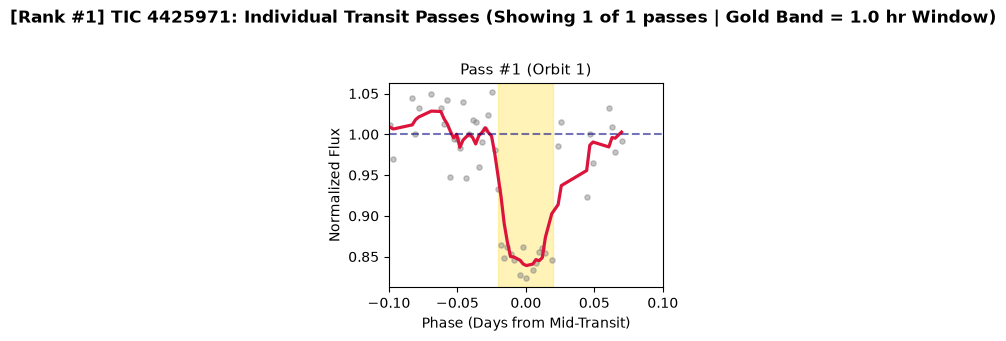

In [18]:
import os
import json
import math

# Inspector configuration parameters
INSPECT_MODE = "ALL_PASSING"
RANK_TO_INSPECT = 1
MAX_PASSES_TO_SHOW = 12
RANKS_TO_SAVE = []
SAVE_CATEGORY = 1     # 1 = "tentative" (candidates/tentative/), 2 = "verified" (candidates/verified/)

# Sort candidates by PASS status first, then descending by SDE
sorted_candidates = sorted(
    high_sde_candidates.values(),
    key=lambda x: ("PASS" in x[0]["Vetting Verdict"], x[0]["SDE (Signal Strength)"]),
    reverse=True
)

# Attach 1-based rank index matching Cell 4 output order
ranked_tuples = [(rank, c[0], c[1], c[2]) for rank, c in enumerate(sorted_candidates, 1)]

if INSPECT_MODE == "ALL_PASSING":
    targets_to_plot = [item for item in ranked_tuples if "PASS" in item[1]["Vetting Verdict"]]
    if len(targets_to_plot) == 0 and len(ranked_tuples) > 0:
        fallback_idx = min(RANK_TO_INSPECT - 1, len(ranked_tuples) - 1)
        print(f"No candidates passed all automated filters in this batch. Showing Rank #{ranked_tuples[fallback_idx][0]} as fallback:")
        targets_to_plot = [ranked_tuples[fallback_idx]]
else:
    target_idx = min(RANK_TO_INSPECT - 1, len(ranked_tuples) - 1)
    targets_to_plot = [ranked_tuples[target_idx]] if len(ranked_tuples) > 0 else []

for rank_num, cand_res, cand_lc, cand_bls in targets_to_plot:
    tic_id = cand_res["TIC ID"]
    safe_name = tic_id.replace(" ", "_")
    p = cand_res["Period (d)"]
    t0 = float(cand_bls.transit_time_at_max_power.value)
    dur = float(cand_bls.duration_at_max_power.value)
    
    # Scale horizontal plot window to 2.5x transit duration, bounded between 0.08 and 0.14 days
    x_zoom = max(min(dur * 2.5, 0.14), 0.08)
    
    print("\n=======================================================")
    print(f"[RANK #{rank_num}] DEEP-DIVE PASS INSPECTION: {tic_id} ({cand_res['Vetting Verdict']})")
    print(f"Period: {p:.4f} d | Duration: {dur*24:.2f} hrs | DipPasses: {cand_res['Transits']} | Dip SNR: {cand_res['Dip SNR']} | Radius: {cand_res['Est. Radius (R_earth)']} R_earth")
    print("=======================================================")
    
    t_arr = np.asarray(cand_lc.time.value, dtype=float)
    f_arr = np.asarray(cand_lc.flux.value, dtype=float)
    
    # Fold timestamps around mid-transit epoch t0
    phase_days = (t_arr - t0 + 0.5 * p) % p - 0.5 * p
    in_window = np.abs(phase_days) <= x_zoom
    orbit_nums = np.round((t_arr - t0) / p).astype(int)
    
    # Filter for discrete orbits containing at least 3 in-transit cadence measurements
    all_orbits = np.unique(orbit_nums[np.abs(phase_days) <= (0.5 * dur)])
    valid_orbits = [orb for orb in all_orbits if np.sum((orbit_nums == orb) & (np.abs(phase_days) <= 0.5 * dur)) >= 3]
    
    orbits_to_show = valid_orbits[:MAX_PASSES_TO_SHOW]
    n_transits = len(orbits_to_show)
    
    if n_transits > 0:
        n_cols = min(4, n_transits)
        n_rows = math.ceil(n_transits / 4)
        
        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(3.8 * n_cols, 3.3 * n_rows),
            sharex=True, sharey=True,
            squeeze=False
        )
        axes_flat = axes.flatten()
        
        for idx, orb in enumerate(orbits_to_show):
            ax = axes_flat[idx]
            mask = (orbit_nums == orb) & in_window
            sort_idx = np.argsort(phase_days[mask])
            t_slice = phase_days[mask][sort_idx]
            f_slice = f_arr[mask][sort_idx]
            
            # Plot raw photometry and 6-point centered rolling mean
            ax.scatter(t_slice, f_slice, color="gray", alpha=0.45, s=14)
            if len(f_slice) >= 5:
                smooth = pd.Series(f_slice).rolling(6, center=True, min_periods=3).mean()
                ax.plot(t_slice, smooth, color="crimson", lw=2.3)
                
            ax.axhline(1.0, color="navy", linestyle="--", alpha=0.55)
            ax.axvspan(-0.5 * dur, 0.5 * dur, color="gold", alpha=0.28, zorder=0)
            ax.set_xlim(-x_zoom, x_zoom)
            ax.set_title(f"Pass #{idx+1} (Orbit {orb})", fontsize=10.5)
            
            if idx >= (n_rows - 1) * n_cols:
                ax.set_xlabel("Phase (Days from Mid-Transit)")
            if idx % n_cols == 0:
                ax.set_ylabel("Normalized Flux")
                
        # Hide unpopulated subplots in trailing grid row
        for unused_idx in range(n_transits, len(axes_flat)):
            axes_flat[unused_idx].set_visible(False)
            
        plt.suptitle(
            f"[Rank #{rank_num}] {tic_id}: Individual Transit Passes (Showing {n_transits} of {len(valid_orbits)} passes | Gold Band = {dur*24:.1f} hr Window)",
            y=1.02, fontsize=12.5, fontweight="bold"
        )
        plt.tight_layout()
        
        # Export candidate artifacts into organized sub-directories if rank is listed in RANKS_TO_SAVE
        if rank_num in RANKS_TO_SAVE:
            subfolder = "tentative" if SAVE_CATEGORY == 1 else "verified"
            save_dir = os.path.join("candidates", subfolder)
            os.makedirs(save_dir, exist_ok=True)
            
            csv_path = os.path.join(save_dir, f"candidate_{safe_name}_lightcurve.csv")
            json_path = os.path.join(save_dir, f"candidate_{safe_name}_summary.json")
            png_path = os.path.join(save_dir, f"candidate_{safe_name}_vetting.png")
            
            cand_lc.to_pandas().to_csv(csv_path, index=False)
            with open(json_path, "w") as f:
                json.dump(cand_res, f, indent=4)
            plt.savefig(png_path, dpi=150, bbox_inches="tight")
            print(f"  -> Saved Rank #{rank_num} ({tic_id}) artifacts to '{save_dir}/'")
            
        plt.show()